In [1]:
import pandas as pd
import os

# Define file paths
data_dir = "../data"
files = {
    "chromium": "01-chromium-feature-flags.csv",
    "gitlab": "01-gitlab-feature-flags.csv",
    "kubernetes": "01-kubernetes-feature-gates.csv",
    "vespa": "01-vespa-feature-flags.csv"
}

# Read CSVs
dfs = {}
for system, filename in files.items():
    file_path = os.path.join(data_dir, filename)
    if os.path.exists(file_path):
        dfs[system] = pd.read_csv(file_path)
        print(f"Loaded {system}: {len(dfs[system])} rows")
    else:
        print(f"Warning: {filename} not found")

# Display first few rows of one as example
if "chromium" in dfs:
    display(dfs["chromium"].head())

Loaded chromium: 1896 rows
Loaded gitlab: 407 rows
Loaded kubernetes: 211 rows
Loaded vespa: 145 rows


,flag_name,has_expiration,expiry_milestone,is_never_expire,expiration_status,owners,owner_count
0,aaudio-per-stream-device-selection,True,150,False,Has Expiration,mjel@google.com;lt-web-apps-team@google.com,2
1,accessible-pdf-form,True,110,False,Has Expiration,bravi@microsoft.com;mohitb@microsoft.com,2
2,account-storage-prefs-themes-search-engines,True,138,False,Has Expiration,ankushkush@google.com;chrome-sync-dev@google.com,2
3,ack-copy-output-request-early-for-view-transition,True,150,False,Has Expiration,hitawala@chromium.org;vasilyt@chromium.org;jon...,3
4,adaptive-button-in-top-toolbar-page-summary,True,140,False,Has Expiration,salg@google.com;chrome-segmentation-platform@g...,2


In [2]:
import subprocess

# Get system version and date info
codebase_dir = "../../codebases"
systems_info = []

def get_git_info(path):
    try:
        # Get short commit hash
        commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=path).decode().strip()
        # Get commit date (YYYY-MM-DD)
        date = subprocess.check_output(["git", "log", "-1", "--format=%ci", commit], cwd=path).decode().strip().split(" ")[0]
        return commit, date
    except Exception as e:
        return "Unknown", "Unknown"

# Chromium
path = os.path.join(codebase_dir, "chromium")
if os.path.exists(path):
    version = "Unknown"
    try:
        ver_file = os.path.join(path, "chrome/VERSION")
        if os.path.exists(ver_file):
            with open(ver_file, "r") as f:
                content = f.read()
                # Extract MAJOR=X
                for line in content.splitlines():
                    if line.startswith("MAJOR="):
                        version = f"M{line.split('=')[1]}"
                        break
    except:
        pass
    commit, date = get_git_info(path)
    systems_info.append({"System": "Chromium", "Version": version, "Commit": commit, "Date": date})

# Kubernetes
path = os.path.join(codebase_dir, "kubernetes")
if os.path.exists(path):
    version = "Unknown"
    try:
        # Get latest tag
        version = subprocess.check_output(["git", "describe", "--tags", "--abbrev=0"], cwd=path).decode().strip()
    except:
        pass
    commit, date = get_git_info(path)
    systems_info.append({"System": "Kubernetes", "Version": version, "Commit": commit, "Date": date})

# GitLab
path = os.path.join(codebase_dir, "gitlab")
if os.path.exists(path):
    version = "Unknown"
    try:
        ver_file = os.path.join(path, "VERSION")
        if os.path.exists(ver_file):
            with open(ver_file, "r") as f:
                version = f"v{f.read().strip()}"
    except:
        pass
    commit, date = get_git_info(path)
    systems_info.append({"System": "GitLab", "Version": version, "Commit": commit, "Date": date})

# Vespa
path = os.path.join(codebase_dir, "vespa")
if os.path.exists(path):
    version = "Unknown"
    try:
        version = subprocess.check_output(["git", "describe", "--tags", "--abbrev=0"], cwd=path).decode().strip()
    except:
        pass
    commit, date = get_git_info(path)
    systems_info.append({"System": "Vespa", "Version": version, "Commit": commit, "Date": date})

# Display info
info_df = pd.DataFrame(systems_info)
display(info_df)

# Extract current version numbers for downstream analysis
def parse_version_num(x):
    try:
        clean = ''.join(c for c in str(x) if c.isdigit() or c == '.')
        parts = clean.split('.')
        if len(parts) >= 2:
            return float(f"{parts[0]}.{parts[1]}")
        return float(parts[0])
    except:
        return None

current_milestone_ch = 133
current_milestone_gl = 17.7
current_release_num = 1.32
current_date = pd.Timestamp.now()
try:
    current_milestone_ch = parse_version_num(info_df[info_df['System']=='Chromium']['Version'].values[0])
    current_milestone_gl = parse_version_num(info_df[info_df['System']=='GitLab']['Version'].values[0])
    current_release_num = parse_version_num(info_df[info_df['System']=='Kubernetes']['Version'].values[0])
    current_date = pd.Timestamp(info_df[info_df['System']=='Vespa']['Date'].values[0])
except:
    pass

,System,Version,Commit,Date
0,Chromium,M145,54e2a848c65e,2025-12-14
1,Kubernetes,v1.36.0-alpha.0,c180d6762d7,2025-12-12
2,GitLab,v18.10.0-pre,f3114f736b1e,2026-02-26
3,Vespa,v8.620.35,f2f0d37afd1,2025-12-22


In [3]:
# Count expiration metadata
results = []

# Helper to extract GitLab flag type from definition_file path
def _extract_gl_type(path):
    try:
        parts = str(path).split('/')
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

# GitLab types with a documented maximum lifespan
GL_TYPES_WITH_EXPIRATION = {'gitlab_com_derisk', 'wip', 'beta', 'experiment'}

for system, df in dfs.items():
    total = len(df)
    has_expiration = 0
    permanent = 0
    
    if system == "chromium":
        # Check 'has_expiration' column (string "True"/"False")
        if "has_expiration" in df.columns:
            has_expiration = df["has_expiration"].astype(str).str.lower().eq("true").sum()
        # Check 'is_never_expire' column
        if "is_never_expire" in df.columns:
            permanent = df["is_never_expire"].astype(str).str.lower().eq("true").sum()
            
    elif system == "kubernetes":
        # Check 'has_expiration' column (boolean or string)
        if "has_expiration" in df.columns:
            has_expiration = df["has_expiration"].astype(str).str.lower().eq("true").sum()
            
    elif system == "vespa":
        # Check 'is_permanent' column. If False, it has expiration.
        if "is_permanent" in df.columns:
            has_expiration = df["is_permanent"].astype(str).str.lower().eq("false").sum()
            permanent = df["is_permanent"].astype(str).str.lower().eq("true").sum()
            
    elif system == "gitlab":
        # Flags in directories with a documented max lifespan count as "With Expiration"
        # (gitlab_com_derisk: 2 mo, wip: 4 mo, beta: 6 mo, experiment: 6 mo)
        # The rest (ops, worker, development, undefined) have no defined expiration
        flag_types = df['definition_file'].apply(_extract_gl_type)
        has_expiration = flag_types.isin(GL_TYPES_WITH_EXPIRATION).sum()
        # No flags are "Permanent" — ops/worker/development/undefined have
        # no documented permanent nature, just no defined lifespan
        permanent = 0
        
    # Flags with no expiration info (neither expiring nor permanent)
    no_info = total - has_expiration - permanent
    
    results.append({
        "System": system.capitalize(),
        "Total Flags": total,
        "With Expiration": has_expiration,
        "Permanent": permanent,
        "No Expiration Info": no_info,
        "% With Expiration": round((has_expiration / total * 100), 1) if total > 0 else 0
    })

# Create summary dataframe
summary_df = pd.DataFrame(results)
display(summary_df)

,System,Total Flags,With Expiration,Permanent,No Expiration Info,% With Expiration
0,Chromium,1896,1752,144,0,92.4
1,Gitlab,407,198,0,209,48.6
2,Kubernetes,211,50,0,161,23.7
3,Vespa,145,53,92,0,36.6


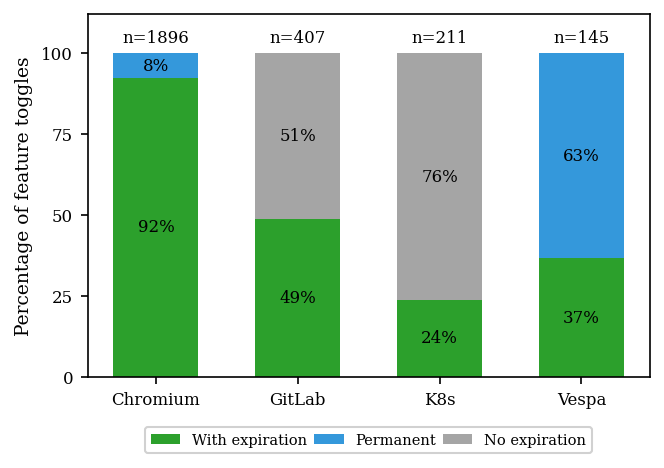

Chart saved to ../assets/rq1-expiration-adoption.pdf and .png


In [4]:
# RQ1 Chart: Adoption of Expiration Metadata (for paper - single column, vertical)
import matplotlib.pyplot as plt
import numpy as np

# Publication-quality style for single column
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

# Prepare data from summary_df
systems = summary_df['System'].tolist()
totals = summary_df['Total Flags'].tolist()
with_exp = summary_df['With Expiration'].tolist()
permanent = summary_df['Permanent'].tolist()
no_info = summary_df['No Expiration Info'].tolist()

# Use shorter names for systems
short_names = {'Chromium': 'Chromium', 'Gitlab': 'GitLab', 'Kubernetes': 'K8s', 'Vespa': 'Vespa'}
systems_short = [short_names.get(s, s) for s in systems]

# Colors matching the study theme
colors = {
    'With Expiration': '#2ca02c',    # Green
    'Permanent': '#3498db',           # Blue  
    'No Expiration Info': '#A5A5A5'   # Gray
}

# Create stacked VERTICAL bar chart - same size as companion chart
fig, ax = plt.subplots(figsize=(4.5, 3.2))

x_pos = np.arange(len(systems))
bar_width = 0.6

# Normalize to 100% stacked bars for better comparison
totals_arr = np.array(totals)
with_exp_pct = np.array(with_exp) / totals_arr * 100
permanent_pct = np.array(permanent) / totals_arr * 100
no_info_pct = np.array(no_info) / totals_arr * 100

# Stack bars vertically
bars1 = ax.bar(x_pos, with_exp_pct, bar_width, label='With expiration', color=colors['With Expiration'])
bars2 = ax.bar(x_pos, permanent_pct, bar_width, bottom=with_exp_pct, label='Permanent', color=colors['Permanent'])
bars3 = ax.bar(x_pos, no_info_pct, bar_width, bottom=with_exp_pct + permanent_pct, label='No expiration', color=colors['No Expiration Info'])

# Add percentage labels on bars
for i, (w, p, n, t) in enumerate(zip(with_exp_pct, permanent_pct, no_info_pct, totals)):
    # With Expiration percentage
    if w > 12:  # Only show if segment is tall enough
        ax.text(i, w/2, f'{w:.0f}%', ha='center', va='center', fontsize=8, color='black')
    elif w > 0:  # Small segment - show to the side
        ax.text(i + 0.35, w/2, f'{w:.0f}%', ha='left', va='center', fontsize=7, color='black')
    # Permanent percentage - lower threshold to 7 so 8% shows inside
    if p > 7:
        ax.text(i, w + p/2, f'{p:.0f}%', ha='center', va='center', fontsize=8, color='black')
    elif p > 0:
        ax.text(i + 0.35, w + p/2, f'{p:.0f}%', ha='left', va='center', fontsize=7, color='black')
    # No Info percentage
    if n > 12:
        ax.text(i, w + p + n/2, f'{n:.0f}%', ha='center', va='center', fontsize=8, color='black')
    # Total count on top
    ax.text(i, 102, f'n={t}', ha='center', va='bottom', fontsize=8, color='black')

ax.set_xticks(x_pos)
ax.set_xticklabels(systems_short)
ax.set_ylabel('Percentage of feature toggles')
ax.set_ylim(0, 112)
ax.set_yticks([0, 25, 50, 75, 100])

# Legend at bottom, horizontal
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, framealpha=0.9, columnspacing=0.5)

plt.tight_layout()
plt.savefig('../assets/rq1-expiration-adoption.pdf', bbox_inches='tight')
plt.savefig('../assets/rq1-expiration-adoption.png', bbox_inches='tight')
plt.show()

print("Chart saved to ../assets/rq1-expiration-adoption.pdf and .png")

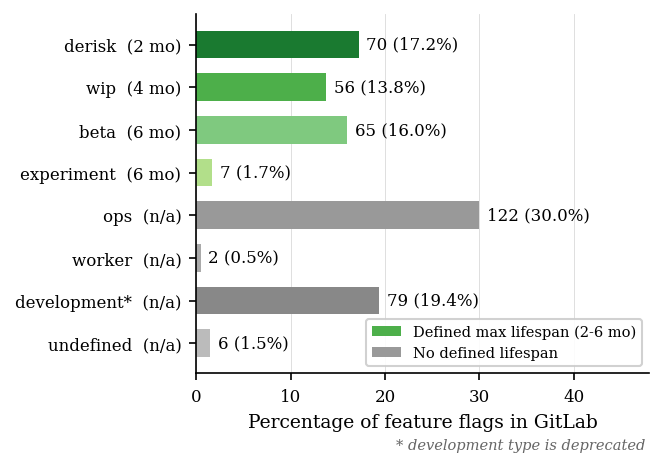


GitLab flag type summary (total=407):
  gitlab_com_derisk     max lifespan: 2 mo          count:  70  (17.2%)
  wip                   max lifespan: 4 mo          count:  56  (13.8%)
  beta                  max lifespan: 6 mo          count:  65  (16.0%)
  experiment            max lifespan: 6 mo          count:   7  (1.7%)
  ops                   max lifespan: n/a           count: 122  (30.0%)
  worker                max lifespan: n/a           count:   2  (0.5%)
  development           max lifespan: n/a           count:  79  (19.4%)
  undefined             max lifespan: n/a           count:   6  (1.5%)

With defined max lifespan (2-6 mo): 198 (48.6%)
No defined lifespan:                209 (51.4%)

Chart saved to ../assets/rq1-gitlab-categories.pdf and .png


In [5]:
# RQ1 Companion: GitLab Feature Flag Types & Lifespans (for paper - single column)
# Based on official documentation: https://docs.gitlab.com/development/feature_flags/
#
# Type              | Max Lifespan       | Notes
# ------------------|--------------------|-----------------------------------
# gitlab_com_derisk | 2 months           | Short-lived, de-risk deployments
# wip               | 4 months           | Work in progress, transition to another type
# beta              | 6 months           | Not yet stable/performant
# experiment        | 6 months           | A/B testing on GitLab.com
# ops               | No defined lifespan| Long-lived operational flags (annual review)
# worker            | No defined lifespan| Special ops for Sidekiq workers
# development       | No defined lifespan| Deprecated in favor of derisk/wip/beta
# undefined         | No defined lifespan| Flags without standard YAML definitions

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

# --- Extract GitLab flag types from the data ---
def extract_type_gl(path):
    try:
        parts = str(path).split('/')
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

df_gl_cat = dfs['gitlab'].copy()
df_gl_cat['flag_type'] = df_gl_cat['definition_file'].apply(extract_type_gl)
gl_total = len(df_gl_cat)
tc = df_gl_cat['flag_type'].value_counts()

# Define categories with official lifespan info, ordered by lifespan (short → long → no defined)
# Green shades = defined max lifespan (these map to "With Expiration" in the adoption chart)
# Gray shades  = no defined lifespan (these map to "No Expiration Info" in the adoption chart)
categories = [
    {'type': 'gitlab_com_derisk', 'label': 'derisk',       'lifespan': '2 mo',        'color': '#1a7a30', 'text_color': 'black'},
    {'type': 'wip',               'label': 'wip',          'lifespan': '4 mo',        'color': '#4daf4a', 'text_color': 'black'},
    {'type': 'beta',              'label': 'beta',         'lifespan': '6 mo',        'color': '#7fc97f', 'text_color': 'black'},
    {'type': 'experiment',        'label': 'experiment',   'lifespan': '6 mo',        'color': '#b2df8a', 'text_color': 'black'},
    {'type': 'ops',               'label': 'ops',          'lifespan': 'n/a',         'color': '#999999', 'text_color': 'black'},
    {'type': 'worker',            'label': 'worker',       'lifespan': 'n/a',         'color': '#aaaaaa', 'text_color': 'black'},
    {'type': 'development',       'label': 'development*', 'lifespan': 'n/a',         'color': '#888888', 'text_color': 'black'},
    {'type': 'undefined',         'label': 'undefined',    'lifespan': 'n/a',         'color': '#bbbbbb', 'text_color': 'black'},
]

for cat in categories:
    cat['count'] = int(tc.get(cat['type'], 0))
    cat['pct'] = cat['count'] / gl_total * 100

# --- Horizontal bar chart (single column width) ---
fig, ax = plt.subplots(figsize=(4.5, 3.2))

y_pos = np.arange(len(categories))[::-1]  # Reverse so shortest lifespan is at top
bar_height = 0.65

for j, cat in enumerate(categories):
    y = y_pos[j]
    bar = ax.barh(y, cat['pct'], bar_height, color=cat['color'])
    # Label outside bar to the right
    ax.text(cat['pct'] + 0.8, y, f"{cat['count']} ({cat['pct']:.1f}%)",
            ha='left', va='center', fontsize=8, color='black')

# Y-axis labels: type name + lifespan
y_labels = [f"{cat['label']}  ({cat['lifespan']})" for cat in categories]
ax.set_yticks(y_pos)
ax.set_yticklabels(y_labels)
ax.set_xlabel('Percentage of feature flags in GitLab')

# Light grid
ax.grid(axis='x', color='#d0d0d0', linestyle='-', linewidth=0.4, alpha=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, 48)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Grouped legend: only two groups now
legend_elements = [
    Patch(facecolor='#4daf4a', label=f'Defined max lifespan (2-6 mo)'),
    Patch(facecolor='#999999', label=f'No defined lifespan'),
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.9)

# Footnote about deprecated type
ax.text(0.99, -0.18, '* development type is deprecated', transform=ax.transAxes,
        fontsize=7, ha='right', va='top', style='italic', color='#666666')

#plt.title(f'GitLab Feature Flag Types (n={gl_total})', fontsize=9, pad=8)
plt.tight_layout()
plt.savefig('../assets/rq1-gitlab-categories.pdf', bbox_inches='tight')
plt.savefig('../assets/rq1-gitlab-categories.png', bbox_inches='tight')
plt.show()

print(f"\nGitLab flag type summary (total={gl_total}):")
for cat in categories:
    print(f"  {cat['type']:20s}  max lifespan: {cat['lifespan']:12s}  count: {cat['count']:3d}  ({cat['pct']:.1f}%)")
print(f"\nWith defined max lifespan (2-6 mo): {sum(c['count'] for c in categories[:4])} ({sum(c['pct'] for c in categories[:4]):.1f}%)")
print(f"No defined lifespan:                {sum(c['count'] for c in categories[4:])} ({sum(c['pct'] for c in categories[4:]):.1f}%)")
print("\nChart saved to ../assets/rq1-gitlab-categories.pdf and .png")

In [6]:
# GitLab Expiration Analysis based on type-specific maximum lifespans
# Policy (from gitlab/doc/development/feature_flags/_index.md):
#   gitlab_com_derisk: 2 months
#   wip: 4 months
#   beta: 6 months
#   experiment: 6 months
#   ops: Unlimited (annual review)
#   worker: Unlimited (special ops)
#   development/undefined: No documented maximum lifespan

import pandas as pd
import numpy as np

# Load GitLab data
df_gl = dfs['gitlab'].copy()

# Extract flag type from definition_file path
def extract_type(path):
    """Extract type from path like .../config/feature_flags/<type>/flag_name.yml"""
    try:
        parts = str(path).split('/')
        # Find 'feature_flags' in path and take the next element
        for i, p in enumerate(parts):
            if p == 'feature_flags' and i + 1 < len(parts):
                return parts[i + 1]
    except:
        pass
    return 'unknown'

df_gl['flag_type'] = df_gl['definition_file'].apply(extract_type)

# GitLab milestone arithmetic
# GitLab releases monthly, but the number of minor versions per major varies:
# Verified from release history (release dates + CHANGELOG):
#   10: 10.0–10.8  (9 releases)    14: 14.0–14.10 (11 releases)
#   11: 11.0–11.11 (12 releases)   15: 15.0–15.11 (12 releases)
#   12: 12.0–12.10 (11 releases)   16: 16.0–16.11 (12 releases)
#   13: 13.0–13.12 (13 releases)   17: 17.0–17.11 (12 releases)
#                                   18: 18.0–18.11 (12 releases)
GITLAB_MAX_MINOR = {
    10: 8, 11: 11, 12: 10, 13: 12, 14: 10,
    15: 11, 16: 11, 17: 11, 18: 11, 19: 11
}
_MIN_MAJOR = min(GITLAB_MAX_MINOR)

def milestone_to_months(ms):
    """Convert 'major.minor' to a sequential milestone index,
    accounting for the actual number of minor versions per major."""
    try:
        parts = str(ms).split('.')
        major = int(parts[0])
        minor = int(parts[1])
        seq = 0
        for m in range(_MIN_MAJOR, major):
            seq += GITLAB_MAX_MINOR.get(m, 11) + 1
        seq += minor
        return seq
    except:
        return None

def months_to_milestone(seq):
    """Convert sequential index back to 'major.minor'."""
    for major in sorted(GITLAB_MAX_MINOR.keys()):
        count = GITLAB_MAX_MINOR[major] + 1
        if seq < count:
            return f"{major}.{seq}"
        seq -= count
    return f"?+{seq}"

# Current version: 18.10
current_version = "18.10"
current_months = milestone_to_months(current_version)
print(f"GitLab version: {current_version} (linear months: {current_months})")

# Maximum lifespan per type (in months/milestones)
lifespan_map = {
    'gitlab_com_derisk': 2,
    'wip': 4,
    'beta': 6,
    'experiment': 6,
    'ops': None,        # Unlimited
    'worker': None,     # Unlimited (special ops)
    'development': None,  # No documented policy
    'undefined': None,    # No documented policy
}

df_gl['introduced_months'] = df_gl['milestone'].apply(milestone_to_months)

# Compute deadline and expiration status
def compute_status(row):
    flag_type = row['flag_type']
    intro_months = row['introduced_months']
    
    lifespan = lifespan_map.get(flag_type, None)
    
    # Types with unlimited lifespan
    if lifespan is None:
        return 'Never Expires'
    
    # Missing milestone - can't compute
    if pd.isna(intro_months):
        return 'Unknown'
    
    deadline_months = intro_months + lifespan
    
    if current_months > deadline_months:
        return 'Expired'
    elif current_months >= deadline_months - 1:
        return 'Expiring Soon'
    else:
        return 'Active'

df_gl['expiration_status'] = df_gl.apply(compute_status, axis=1)

# Summary table
print(f"\n{'='*60}")
print(f"GitLab Feature Flag Expiration Analysis (v{current_version})")
print(f"{'='*60}")
print(f"Total flags: {len(df_gl)}")
print(f"Flags with milestone metadata: {df_gl['introduced_months'].notna().sum()} of {len(df_gl)} ({df_gl['introduced_months'].notna().sum()/len(df_gl)*100:.0f}%)")
print()

# Overall status counts
status_counts = df_gl['expiration_status'].value_counts()
print("Expiration Status (all flags):")
print("-" * 40)
for status in ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown']:
    count = status_counts.get(status, 0)
    pct = count / len(df_gl) * 100
    print(f"  {status:<16}: {count:>4} ({pct:.1f}%)")

# Breakdown by type
print(f"\n{'='*60}")
print("Breakdown by Flag Type:")
print(f"{'='*60}")
type_status = pd.crosstab(df_gl['flag_type'], df_gl['expiration_status'], margins=True)
# Reorder columns
col_order = [c for c in ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown', 'All'] if c in type_status.columns]
type_status = type_status[col_order]
display(type_status)

# Summary for paper: same format as other 3 systems
print(f"\n{'='*60}")
print("Summary (comparable to Chromium, Kubernetes, Vespa):")
print(f"{'='*60}")
expired = status_counts.get('Expired', 0)
expiring_soon = status_counts.get('Expiring Soon', 0)
active = status_counts.get('Active', 0)
never_expires = status_counts.get('Never Expires', 0)
unknown = status_counts.get('Unknown', 0)

summary_data = {
    'Category': ['Expired', 'Expiring Soon', 'Active', 'Never Expires', 'Unknown (no milestone)'],
    'Count': [expired, expiring_soon, active, never_expires, unknown],
    '%': [f"{expired/len(df_gl)*100:.1f}%", f"{expiring_soon/len(df_gl)*100:.1f}%", 
          f"{active/len(df_gl)*100:.1f}%", f"{never_expires/len(df_gl)*100:.1f}%",
          f"{unknown/len(df_gl)*100:.1f}%"]
}
summary_table = pd.DataFrame(summary_data)
display(summary_table)


GitLab version: 18.10 (linear months: 102)

GitLab Feature Flag Expiration Analysis (v18.10)
Total flags: 407
Flags with milestone metadata: 403 of 407 (99%)

Expiration Status (all flags):
----------------------------------------
  Expired         :  120 (29.5%)
  Expiring Soon   :   37 (9.1%)
  Active          :   41 (10.1%)
  Never Expires   :  209 (51.4%)
  Unknown         :    0 (0.0%)

Breakdown by Flag Type:


expiration_status,Expired,Expiring Soon,Active,Never Expires,All
flag_type,,,,,
beta,27,5,33,0,65
development,0,0,0,79,79
experiment,5,1,1,0,7
gitlab_com_derisk,47,23,0,0,70
ops,0,0,0,122,122
undefined,0,0,0,6,6
wip,41,8,7,0,56
worker,0,0,0,2,2
All,120,37,41,209,407



Summary (comparable to Chromium, Kubernetes, Vespa):


,Category,Count,%
0,Expired,120,29.5%
1,Expiring Soon,37,9.1%
2,Active,41,10.1%
3,Never Expires,209,51.4%
4,Unknown (no milestone),0,0.0%


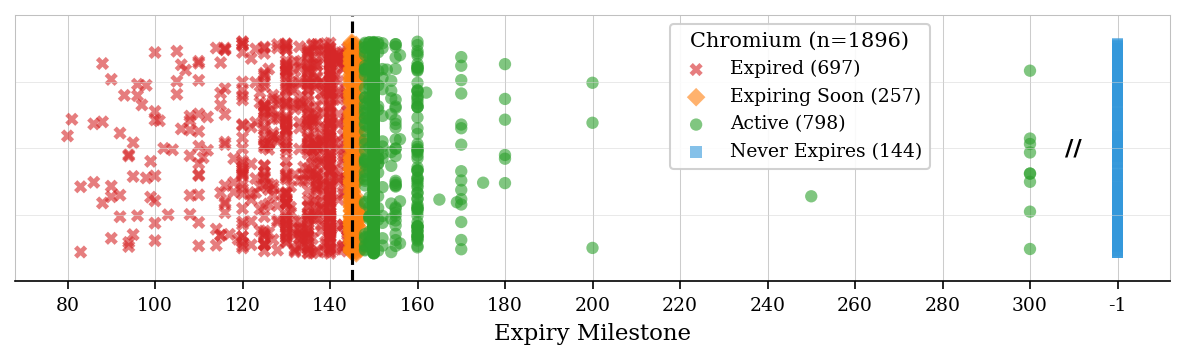

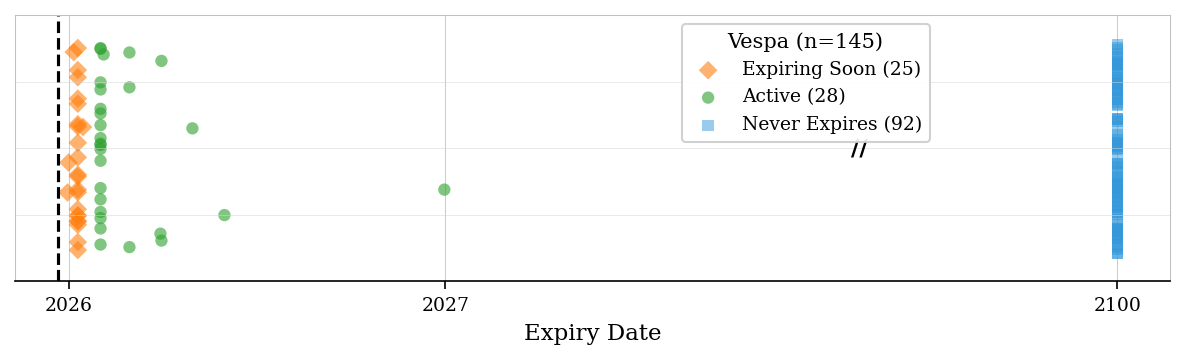

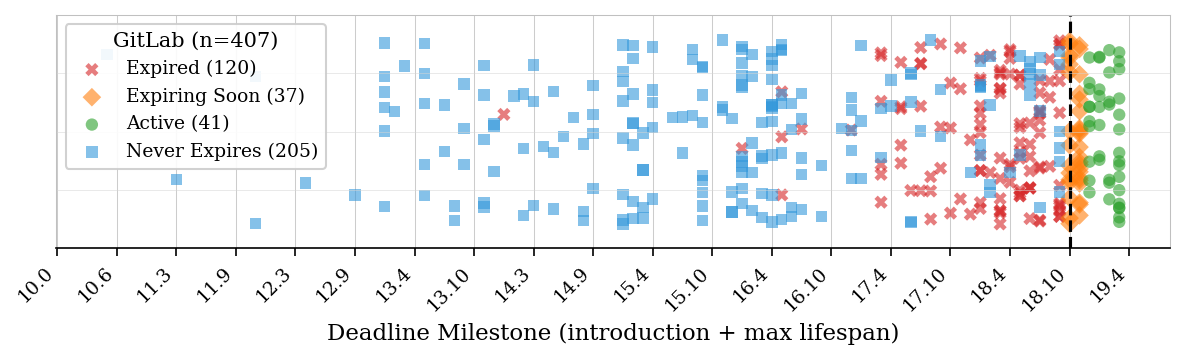

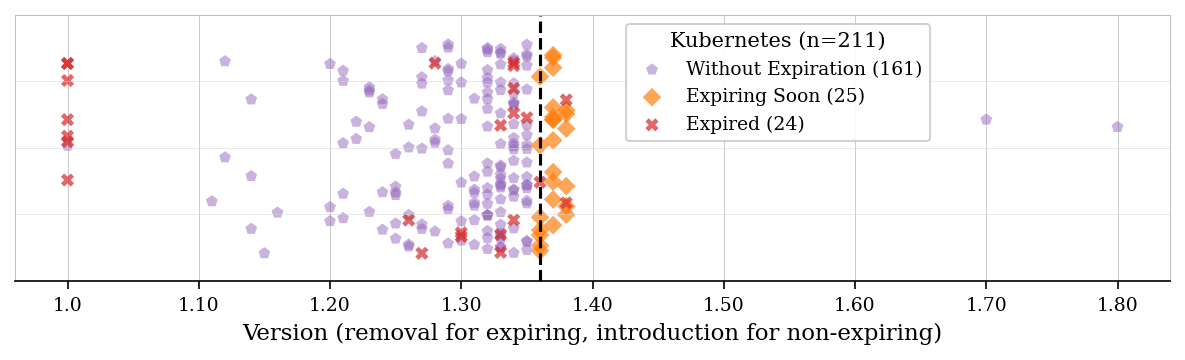

All individual charts saved to ../assets/strip-{chromium,vespa,gitlab,kubernetes}.{pdf,png}


In [7]:
# Individual strip plots for each system - publication-quality, one per figure
# Inspired by the GitLab strip plot dimensions (8" x 2.5") for readability
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.dpi': 150,
    'savefig.dpi': 300,
})

np.random.seed(42)

color_map = {
    'Expired': '#d62728',
    'Expiring Soon': '#ff7f0e',
    'Active': '#2ca02c',
    'Never Expires': '#3498db',
    'Without Expiration': '#9467bd'
}

marker_map = {
    'Expired': 'X',
    'Expiring Soon': 'D',
    'Active': 'o',
    'Never Expires': 's',
    'Without Expiration': 'p'
}

size_map = {
    'Expired': 40,
    'Expiring Soon': 40,
    'Active': 35,
    'Never Expires': 30,
    'Without Expiration': 35
}

def style_strip_ax(ax):
    """Clean strip-plot styling for paper."""
    ax.spines['bottom'].set_color('black')
    ax.spines['bottom'].set_linewidth(0.8)
    for side in ['top', 'left', 'right']:
        ax.spines[side].set_color('#c0c0c0')
        ax.spines[side].set_linewidth(0.5)
    ax.set_yticks([])
    ax.set_ylim(-0.5, 0.5)
    ax.tick_params(axis='x', direction='out', length=4, width=0.8)
    # Vertical grid lines
    ax.grid(axis='x', color='#c0c0c0', linestyle='-', linewidth=0.5, alpha=0.8)
    # Horizontal grid lines at y=0 and y=±0.25 for visual anchoring
    for yval in [-0.25, 0, 0.25]:
        ax.axhline(y=yval, color='#d5d5d5', linestyle='-', linewidth=0.4, alpha=0.6)
    ax.set_axisbelow(True)

def scatter_cat(ax, x, status, s=None, alpha=0.6, label=None):
    """Scatter with random y-jitter."""
    if s is None:
        s = size_map[status]
    y = np.random.uniform(-0.4, 0.4, len(x))
    ax.scatter(x, y, c=color_map[status], marker=marker_map[status],
               edgecolors='none', s=s, alpha=alpha, label=label)

def parse_version_num(x):
    try:
        clean = ''.join(c for c in str(x) if c.isdigit() or c == '.')
        parts = clean.split('.')
        if len(parts) >= 2:
            return float(f"{parts[0]}.{parts[1]}")
        return float(parts[0])
    except:
        return None

# ============================================================
# (a) CHROMIUM - Individual Chart
# ============================================================
fig, ax = plt.subplots(figsize=(8, 2.5))

df_c = dfs['chromium'].copy()
df_c['has_expiration'] = df_c['has_expiration'].astype(str).str.lower() == 'true'
df_c['is_never_expire'] = df_c['is_never_expire'].astype(str).str.lower() == 'true'
df_c['expiry_milestone'] = pd.to_numeric(df_c['expiry_milestone'], errors='coerce')

df_with_ms = df_c[(df_c['has_expiration']) & (~df_c['is_never_expire'])].copy()
df_never = df_c[df_c['is_never_expire'] == True]

df_with_ms['exp_status'] = 'Active'
df_with_ms.loc[df_with_ms['expiry_milestone'] < current_milestone_ch, 'exp_status'] = 'Expired'
df_with_ms.loc[(df_with_ms['expiry_milestone'] >= current_milestone_ch) &
               (df_with_ms['expiry_milestone'] < current_milestone_ch + 3), 'exp_status'] = 'Expiring Soon'

for st in ['Expired', 'Expiring Soon', 'Active']:
    sub = df_with_ms[df_with_ms['exp_status'] == st]
    if len(sub) > 0:
        scatter_cat(ax, sub['expiry_milestone'].values, st, label=f'{st} ({len(sub)})')

max_ms = df_with_ms['expiry_milestone'].max()
min_ms = df_with_ms['expiry_milestone'].min()

if len(df_never) > 0:
    never_x = max_ms + 20
    scatter_cat(ax, np.full(len(df_never), never_x), 'Never Expires',
                label=f'Never Expires ({len(df_never)})')
    ax.text(max_ms + 10, 0, '//', fontsize=11, ha='center', va='center', fontweight='bold')

ch_tick_start = int(min_ms // 20 * 20)
ch_tick_end = int(max_ms) + 20
ch_data_ticks = list(range(ch_tick_start, ch_tick_end, 20))
if len(df_never) > 0:
    ax.set_xticks(ch_data_ticks + [never_x])
    ax.set_xticklabels([str(t) for t in ch_data_ticks] + ['-1'])
else:
    ax.set_xticks(ch_data_ticks)

ax.axvline(x=current_milestone_ch, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Expiry Milestone')
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=9, framealpha=0.9,
          title=f'Chromium (n={len(df_c)})', title_fontsize=10)

plt.tight_layout()
plt.savefig('../assets/strip-chromium.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-chromium.png', bbox_inches='tight')
plt.show()

# ============================================================
# (b) VESPA - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_v = dfs['vespa'].copy()
df_v['expires_at'] = pd.to_datetime(df_v['expires_at'], errors='coerce')
df_v['is_permanent'] = df_v['is_permanent'].astype(str).str.lower() == 'true'

df_v_exp = df_v[~df_v['is_permanent']].copy()
df_v_perm = df_v[df_v['is_permanent']].copy()

df_v_exp['exp_status'] = 'Active'
df_v_exp.loc[df_v_exp['expires_at'] < current_date, 'exp_status'] = 'Expired'
df_v_exp.loc[(df_v_exp['expires_at'] >= current_date) &
             (df_v_exp['expires_at'] < current_date + pd.Timedelta(days=30)), 'exp_status'] = 'Expiring Soon'

for st in ['Expired', 'Expiring Soon', 'Active']:
    sub = df_v_exp[df_v_exp['exp_status'] == st]
    if len(sub) > 0:
        y = np.random.uniform(-0.4, 0.4, len(sub))
        ax.scatter(sub['expires_at'], y, c=color_map[st], marker=marker_map[st],
                   edgecolors='none', s=size_map[st], alpha=0.6, label=f'{st} ({len(sub)})')

if len(df_v_perm) > 0:
    if len(df_v_exp) > 0:
        last_exp_date = df_v_exp['expires_at'].max()
        first_exp_date = df_v_exp['expires_at'].min()
    else:
        last_exp_date = current_date
        first_exp_date = current_date - pd.Timedelta(days=365)

    min_visual_end = pd.Timestamp('2027-06-01')
    if last_exp_date < min_visual_end:
        last_exp_date = min_visual_end

    visual_gap = pd.Timedelta(days=500)
    perm_visual_date = last_exp_date + visual_gap

    y = np.random.uniform(-0.4, 0.4, len(df_v_perm))
    ax.scatter([perm_visual_date]*len(df_v_perm), y, c=color_map['Never Expires'],
               marker=marker_map['Never Expires'], edgecolors='none', s=size_map['Never Expires'],
               alpha=0.5, label=f'Never Expires ({len(df_v_perm)})')

    years = pd.date_range(start=first_exp_date, end=last_exp_date, freq='YS')
    if len(years) == 0 or years[-1].year < last_exp_date.year:
        years = years.union([pd.Timestamp(f"{last_exp_date.year}-01-01")])
    ticks = list(years) + [perm_visual_date]
    labels = [t.strftime('%Y') for t in ticks[:-1]] + ["2100"]
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels)

    break_pos = last_exp_date + (visual_gap / 2)
    ax.text(break_pos, 0, '//', fontsize=11, ha='center', va='center', fontweight='bold')

ax.axvline(x=current_date, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Expiry Date')
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=9, framealpha=0.9,
          title=f'Vespa (n={len(df_v)})', title_fontsize=10)

plt.tight_layout()
plt.savefig('../assets/strip-vespa.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-vespa.png', bbox_inches='tight')
plt.show()

# ============================================================
# (c) GITLAB - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_gl_plot = df_gl.copy()
df_gl_plot = df_gl_plot[df_gl_plot['introduced_months'].notna()].copy()

def get_x_position(row):
    flag_type = row['flag_type']
    intro = row['introduced_months']
    lifespan = lifespan_map.get(flag_type, None)
    if lifespan is None:
        return intro
    return intro + lifespan

df_gl_plot['x_pos'] = df_gl_plot.apply(get_x_position, axis=1)

for st in ['Expired', 'Expiring Soon', 'Active', 'Never Expires']:
    sub = df_gl_plot[df_gl_plot['expiration_status'] == st]
    if len(sub) > 0:
        scatter_cat(ax, sub['x_pos'].values, st, alpha=0.6,
                    label=f'{st} ({len(sub)})')

ax.axvline(x=current_months, color='black', linestyle='--', linewidth=1.5)

all_x = df_gl_plot['x_pos'].dropna()
min_m = int(all_x.min())
max_m = int(all_x.max())
tick_positions = list(range(min_m - (min_m % 6), max_m + 6, 6))
tick_labels = [months_to_milestone(m) for m in tick_positions]
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha='right')

ax.set_xlabel('Deadline Milestone (introduction + max lifespan)')
style_strip_ax(ax)
ax.legend(loc='upper left', fontsize=9, framealpha=0.9,
          title=f'GitLab (n={len(df_gl)})', title_fontsize=10)

plt.tight_layout()
plt.savefig('../assets/strip-gitlab.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-gitlab.png', bbox_inches='tight')
plt.show()

# ============================================================
# (d) KUBERNETES - Individual Chart
# ============================================================
np.random.seed(42)
fig, ax = plt.subplots(figsize=(8, 2.5))

df_k = dfs['kubernetes'].copy()
df_k['has_expiration'] = df_k['has_expiration'].astype(str).str.lower() == 'true'
df_k['removal_ver_num'] = df_k['removal_version'].apply(parse_version_num)
df_k['added_ver_num'] = df_k['version_added'].apply(parse_version_num)

is_deprecated = df_k['stage'] == 'Deprecated'
is_expired = df_k['has_expiration'] & (df_k['removal_ver_num'] < current_release_num)
df_k['is_stale'] = is_deprecated | is_expired

df_k_stale = df_k[df_k['is_stale']].copy()
df_k_not_stale = df_k[~df_k['is_stale']].copy()

df_k_stale['version_num'] = df_k_stale['removal_ver_num'].fillna(df_k_stale['added_ver_num'])
df_k_stale = df_k_stale.dropna(subset=['version_num'])

df_k_with_exp = df_k_not_stale[df_k_not_stale['has_expiration']].copy()
df_k_without_exp = df_k_not_stale[~df_k_not_stale['has_expiration']].copy()

df_k_with_exp['version_num'] = df_k_with_exp['removal_ver_num']
df_k_with_exp = df_k_with_exp.dropna(subset=['version_num'])
df_k_with_exp['exp_status'] = 'Active'
df_k_with_exp.loc[(df_k_with_exp['version_num'] >= current_release_num) &
                  (df_k_with_exp['version_num'] < current_release_num + 0.02), 'exp_status'] = 'Expiring Soon'

df_k_without_exp['version_num'] = df_k_without_exp['added_ver_num']
df_k_without_exp = df_k_without_exp.dropna(subset=['version_num'])

if len(df_k_without_exp) > 0:
    scatter_cat(ax, df_k_without_exp['version_num'].values, 'Without Expiration', alpha=0.5,
                label=f'Without Expiration ({len(df_k_without_exp)})')

for st in ['Expiring Soon', 'Active']:
    sub = df_k_with_exp[df_k_with_exp['exp_status'] == st]
    if len(sub) > 0:
        scatter_cat(ax, sub['version_num'].values, st, alpha=0.7,
                    label=f'{st} ({len(sub)})')

if len(df_k_stale) > 0:
    scatter_cat(ax, df_k_stale['version_num'].values, 'Expired', alpha=0.7,
                label=f'Expired ({len(df_k_stale)})')

ax.axvline(current_release_num, color='black', linestyle='--', linewidth=1.5)
ax.set_xlabel('Version (removal for expiring, introduction for non-expiring)')

all_k8s_x = pd.concat([df_k_stale['version_num'], df_k_with_exp['version_num'],
                        df_k_without_exp['version_num']], ignore_index=True)
k8s_min = all_k8s_x.min()
k8s_max = all_k8s_x.max()
k8s_ticks = np.arange(int(k8s_min * 100) // 10 * 10 / 100,
                       k8s_max + 0.10, 0.10)
k8s_tick_labels = [f'{int(t)}.{int(round((t % 1)*100))}' for t in k8s_ticks]
ax.set_xticks(k8s_ticks)
ax.set_xticklabels(k8s_tick_labels)
style_strip_ax(ax)
ax.legend(loc='upper right', bbox_to_anchor=(0.8, 1.0), fontsize=9, framealpha=0.9,
          title=f'Kubernetes (n={len(df_k)})', title_fontsize=10)

plt.tight_layout()
plt.savefig('../assets/strip-kubernetes.pdf', bbox_inches='tight')
plt.savefig('../assets/strip-kubernetes.png', bbox_inches='tight')
plt.show()

print("All individual charts saved to ../assets/strip-{chromium,vespa,gitlab,kubernetes}.{pdf,png}")
